In [40]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [41]:
df = df[df['job_title_short'] == 'Data Scientist'].copy()


In [51]:
# Explode the 'job_skills' into individual rows
df_exploded= df.explode('job_skills')
skill_stats= df_exploded.groupby('job_skills').agg(
    median_salary=('salary_year_avg', 'median'),
    skill_count =('job_skills', 'count')
)
# Limit to the top  skills by highest salary
skill_stats= skill_stats.sort_values(by ='skill_count' , ascending = False).head(10)
skill_stats

,median_salary,skill_count
job_skills,,
python,130500.0,113711
sql,132500.0,78982
r,125000.0,59566
sas,119000.0,29534
tableau,125000.0,29445
aws,132500.0,26256
spark,135000.0,24286
azure,127500.0,21664
tensorflow,140000.0,19153


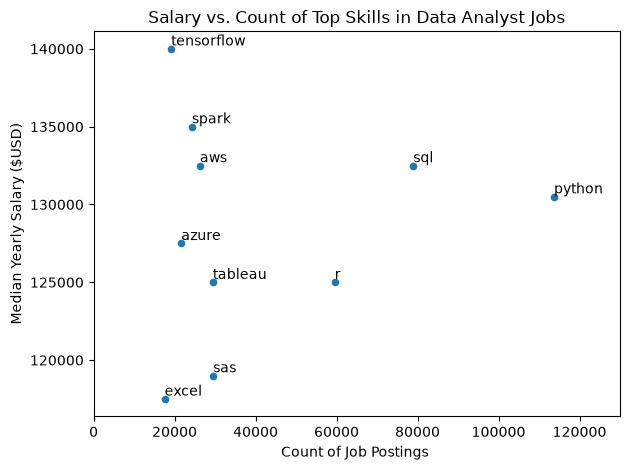

In [47]:
skill_stats.plot(kind = 'scatter', x= 'skill_count', y = 'median_salary')
plt.title('Salary vs. Count of Top Skills in Data Analyst Jobs')
plt.xlabel('Count of Job Postings ')
plt.ylabel('Median Yearly Salary ($USD)')
plt.xlim(0, 130000)
plt.tight_layout()
#text: Add text annotations to the plot by using for loop 
for i , txt in enumerate(skill_stats.index) : 
    plt.text(skill_stats['skill_count'].iloc[i], skill_stats['median_salary'].iloc[i] , txt  , va = 'bottom' )
plt.show()

In [52]:
# Explode the 'job_skills' into individual rows
df_exploded= df.explode('job_skills')
skill_stats= df_exploded.groupby('job_skills').agg(
    median_salary=('salary_year_avg', 'median'),
    skill_count =('job_skills', 'count')
)
# Limit to the top  skills by highest salary
skill_count = 20
skill_stats= skill_stats.sort_values(by ='skill_count' , ascending = False).head(skill_count)
skill_stats

,median_salary,skill_count
job_skills,,
python,130500.0,113711
sql,132500.0,78982
r,125000.0,59566
sas,119000.0,29534
tableau,125000.0,29445
aws,132500.0,26256
spark,135000.0,24286
azure,127500.0,21664
tensorflow,140000.0,19153


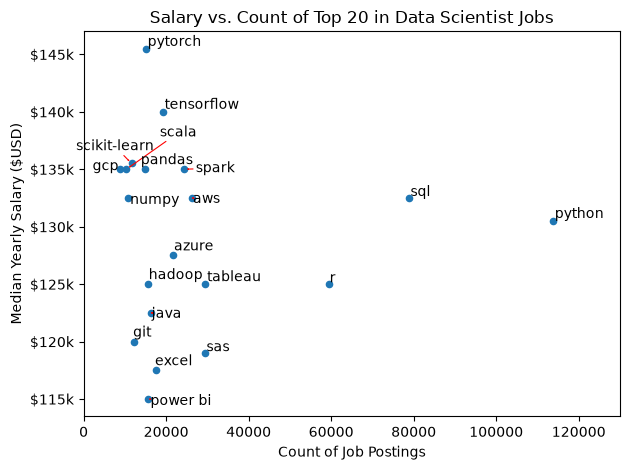

In [ ]:
from adjustText import adjust_text
from matplotlib.ticker import FuncFormatter  
skill_stats.plot(kind='scatter', x='skill_count', y='median_salary')
plt.title(f'Salary vs. Count of Top {skill_count} in Data Scientist Jobs')
plt.xlabel('Count of Job Postings')
plt.ylabel('Median Yearly Salary ($USD)')
plt.xlim(0, 130000)
# Format Y-axis ticks to look like $120k, $130k, etc.
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f'${int(y/ 1000)}k'))
plt.tight_layout()
# Prepare texts for adjustText
texts = []
for i, txt in enumerate(skill_stats.index):
  # Capture the text object and append it to the list!
  t = plt.text(
      skill_stats['skill_count'].iloc[i],
      skill_stats['median_salary'].iloc[i],
      txt,
      fontsize=10,
  )
  texts.append(t)

# Adjust text to avoid overlap
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='red', lw=0.8))

plt.show()